In [49]:
import pandas as pd
from sklearn.feature_selection import f_classif
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler




In [50]:
columns = [
    "Class",
    "Alcohol",
 	"Malic acid",
 	"Ash",
	"Alcalinity of ash",
 	"Magnesium",
	"Total phenols",
 	"Flavanoids",
 	"Nonflavanoid phenols",
 	"Proanthocyanins",
	"Color intensity",
 	"Hue",
 	"OD280/OD315 of diluted wines",
 	"Proline" 
]

df = pd.read_csv("../dataset/raw/UCI/wine.data",
    header=None,
    names = columns
)

print(f"(row , column) = {df.shape}\n")
print(f"column names = {df.columns.tolist()}\n")
print(f"grape classes = {df["Class"].unique().tolist()}\n")

(row , column) = (178, 14)

column names = ['Class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315 of diluted wines', 'Proline']

grape classes = [1, 2, 3]



In [51]:
print("Sum Missing values    :", int(df.isna().sum().sum()))
print("Sum Duplicated values    :", int(df.duplicated().sum()))
print("Sum Unlabeled data  :", int(df['Class'].isna().sum()))

counts = df["Class"].value_counts().sort_index()
dist = pd.DataFrame({"example": counts, "ratio_%": (counts / len(df) * 100).round(1)})
dist.index.name = "Class"
dist

Sum Missing values    : 0
Sum Duplicated values    : 0
Sum Unlabeled data  : 0


,example,ratio_%
Class,,
1,59,33.1
2,71,39.9
3,48,27.0


In [52]:
#statistics and skew(data is simetric or not)
desc = df[columns].describe().T
desc["skew"] = df[columns].skew()
desc[["mean","std","50%","min","max","skew"]].round(3)

,mean,std,50%,min,max,skew
Class,1.938,0.775,2.000,1.00,3.00,0.107
Alcohol,13.001,0.812,13.050,11.03,14.83,-0.051
Malic acid,2.336,1.117,1.865,0.74,5.80,1.040
Ash,2.367,0.274,2.360,1.36,3.23,-0.177
Alcalinity of ash,19.495,3.340,19.500,10.60,30.00,0.213
Magnesium,99.742,14.282,98.000,70.00,162.00,1.098
Total phenols,2.295,0.626,2.355,0.98,3.88,0.087
Flavanoids,2.029,0.999,2.135,0.34,5.08,0.025
Nonflavanoid phenols,0.362,0.124,0.340,0.13,0.66,0.450
Proanthocyanins,1.591,0.572,1.555,0.41,3.58,0.517


In [53]:
m = df[columns].mean()
print(f"Highest feature with mean : {m.idxmax()} ({m.max():.1f})")
print(f"Lowest feature with mean : {m.idxmin()} ({m.min():.3f})")
print(f"Rate                       : {m.max() / m.min():,.0f} times")

Highest feature with mean : Proline (746.9)
Lowest feature with mean : Nonflavanoid phenols (0.362)
Rate                       : 2,064 times


In [54]:
Q1, Q3 = df[columns].quantile(0.25), df[columns].quantile(0.75)
IQR = Q3 - Q1
out = ((df[columns] < Q1 - 1.5 * IQR) | (df[columns] > Q3 + 1.5 * IQR)).sum()
out[out > 0].sort_values(ascending=False).to_frame("outlier_number")

,outlier_number
Alcalinity of ash,4
Color intensity,4
Magnesium,4
Ash,3
Malic acid,3
Proanthocyanins,2
Hue,1


In [55]:
df.groupby("Class")[columns].mean().T.round(2)

Class,1,2,3
Class,1.00,2.00,3.00
Alcohol,13.74,12.28,13.15
Malic acid,2.01,1.93,3.33
Ash,2.46,2.24,2.44
Alcalinity of ash,17.04,20.24,21.42
Magnesium,106.34,94.55,99.31
Total phenols,2.84,2.26,1.68
Flavanoids,2.98,2.08,0.78
Nonflavanoid phenols,0.29,0.36,0.45
Proanthocyanins,1.90,1.63,1.15


In [56]:
F, p = f_classif(df[columns], df["Class"])
anova = pd.DataFrame({"F": F, "p": p}, index=columns).sort_values("F", ascending=False)
anova.round(4)

c:\Users\austu\OneDrive\Desktop\AI-ML\projects\Wine_Quality\venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


,F,p
Class,inf,0.0
Flavanoids,233.9259,0.0
Proline,207.9204,0.0
OD280/OD315 of diluted wines,189.9723,0.0
Alcohol,135.0776,0.0
Color intensity,120.6640,0.0
Hue,101.3168,0.0
Total phenols,93.7330,0.0
Malic acid,36.9434,0.0
Alcalinity of ash,35.7716,0.0


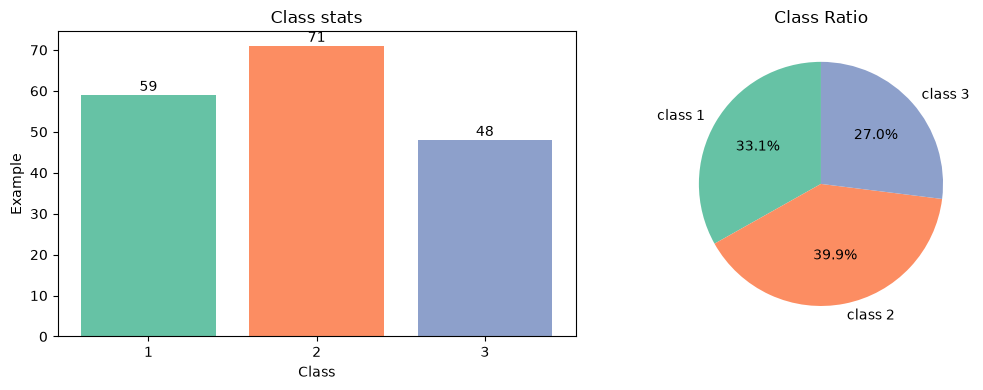

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cols = sns.color_palette("Set2", 3)
axes[0].bar(counts.index.astype(str), counts.values, color=cols)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1, str(v), ha="center")
axes[0].set_title("Class stats"); axes[0].set_xlabel("Class"); axes[0].set_ylabel("Example")
axes[1].pie(counts.values, labels=[f"class {c}" for c in counts.index], autopct="%1.1f%%", colors=cols, startangle=90)
axes[1].set_title("Class Ratio")
plt.tight_layout(); plt.show()

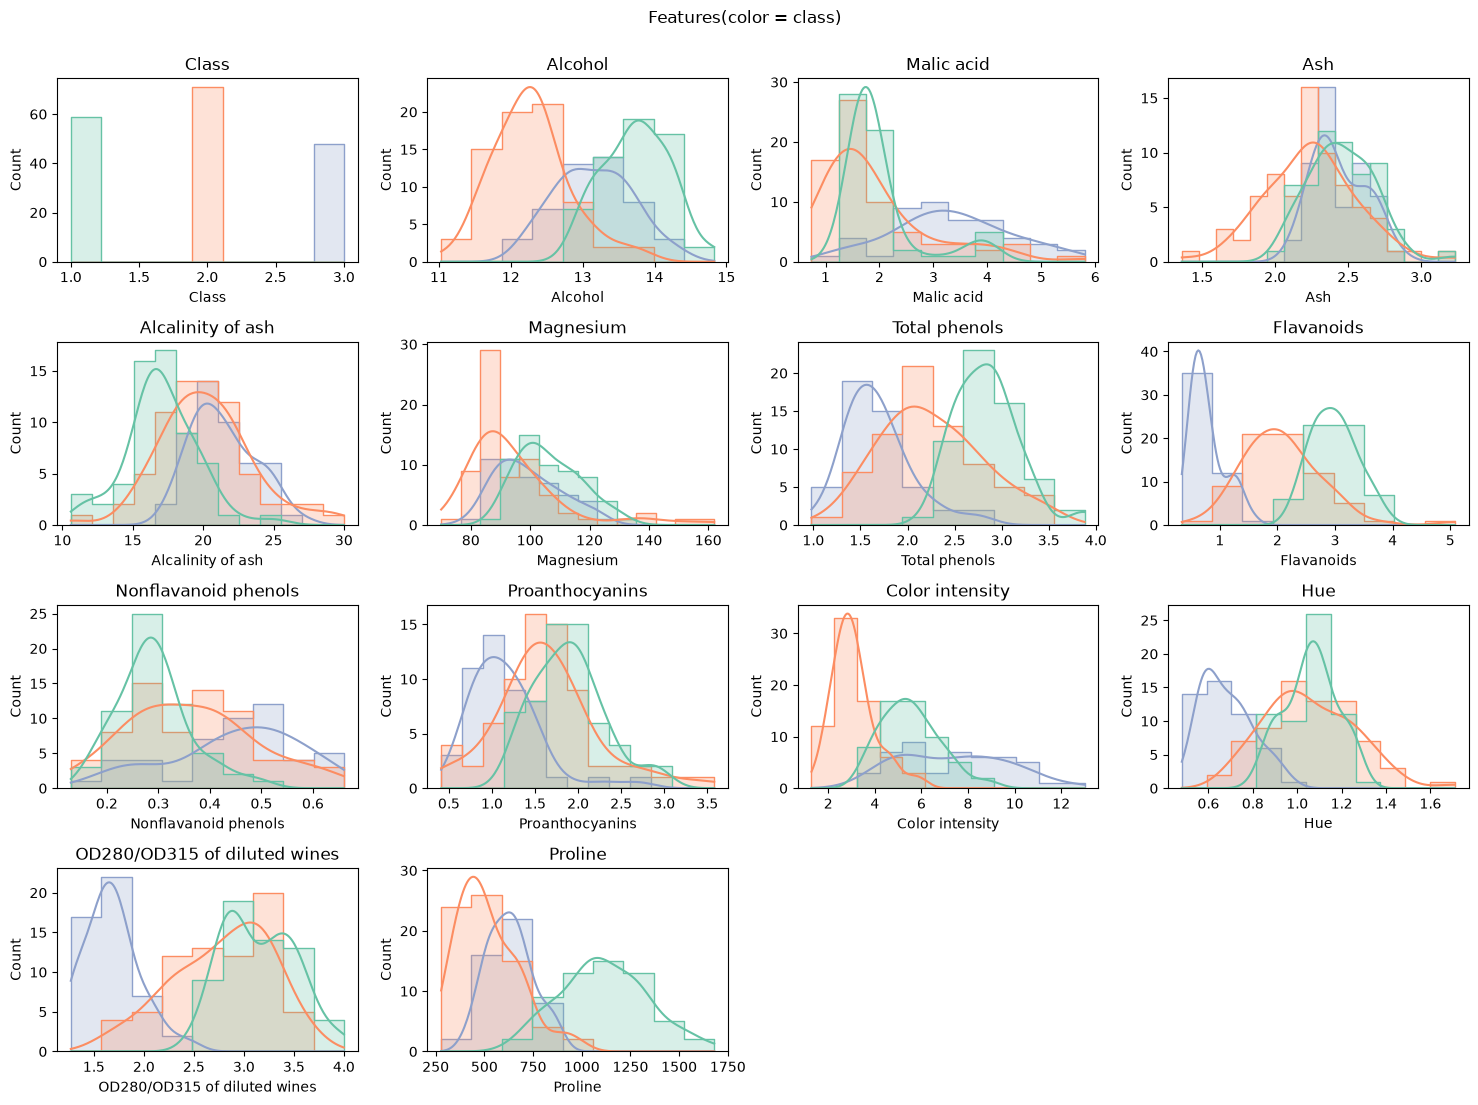

In [58]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, f in zip(axes.ravel(), columns):
    sns.histplot(data=df, x=f, hue="Class", palette="Set2", kde=True, element="step", ax=ax, legend=False)
    ax.set_title(f)
for ax in axes.ravel()[len(columns):]:
    ax.axis("off")
plt.suptitle("Features(color = class)", y=1.0)
plt.tight_layout(); plt.show()

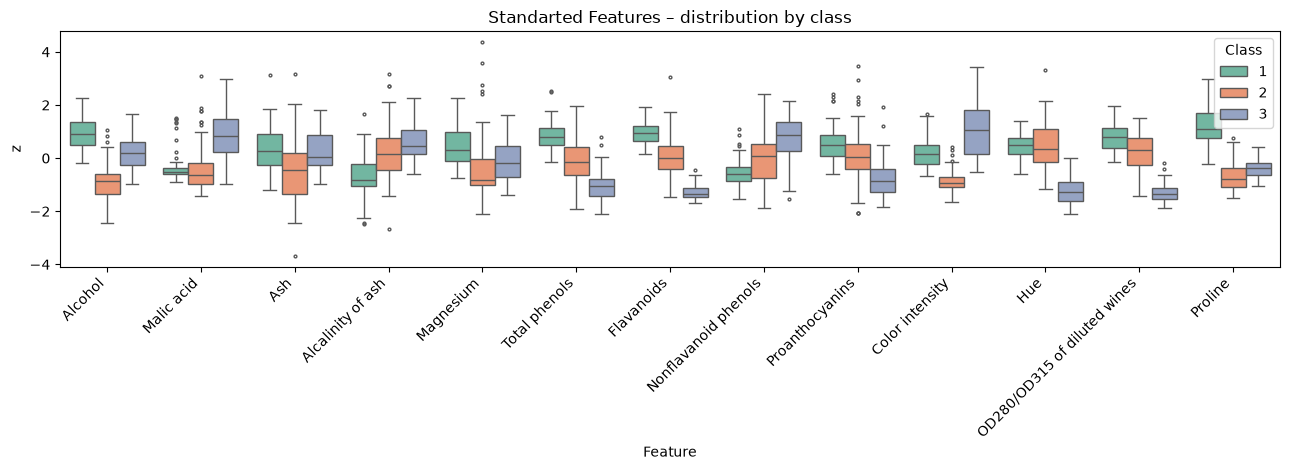

In [60]:
Z = pd.DataFrame(StandardScaler().fit_transform(df[columns]), columns=columns)
Z["Class"] = df["Class"].values
long = Z.melt(id_vars="Class", var_name="Feature", value_name="z")
plt.figure(figsize=(13, 4.8))
sns.boxplot(data=long, x="Feature", y="z", hue="Class", palette="Set2", fliersize=2)
plt.xticks(rotation=45, ha="right"); plt.title("Standarted Features – distribution by class")
plt.tight_layout(); plt.show()